# Titanic Exploratory Data Analysis

## Purpose
I will explore the Titanic passenger dataset to understand survival patterns,
missing data, and relationships between passenger details and survival.

Import the libraries

In [3]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")

Load the data

In [4]:
df = pd.read_csv("train.csv")

print("Rows and columns:", df.shape)
df.head()

Rows and columns: (891, 12)


,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


Check the columns and data types

In [5]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    int64  
 2   Pclass       891 non-null    int64  
 3   Name         891 non-null    object 
 4   Sex          891 non-null    object 
 5   Age          714 non-null    float64
 6   SibSp        891 non-null    int64  
 7   Parch        891 non-null    int64  
 8   Ticket       891 non-null    object 
 9   Fare         891 non-null    float64
 10  Cabin        204 non-null    object 
 11  Embarked     889 non-null    object 
dtypes: float64(2), int64(5), object(5)
memory usage: 83.7+ KB


Count missing values and duplicate rows

In [6]:
df.isnull().sum()

PassengerId      0
Survived         0
Pclass           0
Name             0
Sex              0
Age            177
SibSp            0
Parch            0
Ticket           0
Fare             0
Cabin          687
Embarked         2
dtype: int64

Look at number summaries

In [7]:
df.describe()

,PassengerId,Survived,Pclass,Age,SibSp,Parch,Fare
count,891.000000,891.000000,891.000000,714.000000,891.000000,891.000000,891.000000
mean,446.000000,0.383838,2.308642,29.699118,0.523008,0.381594,32.204208
std,257.353842,0.486592,0.836071,14.526497,1.102743,0.806057,49.693429
min,1.000000,0.000000,1.000000,0.420000,0.000000,0.000000,0.000000
25%,223.500000,0.000000,2.000000,20.125000,0.000000,0.000000,7.910400
50%,446.000000,0.000000,3.000000,28.000000,0.000000,0.000000,14.454200
75%,668.500000,1.000000,3.000000,38.000000,1.000000,0.000000,31.000000
max,891.000000,1.000000,3.000000,80.000000,8.000000,6.000000,512.329200


Count how many passengers survived

In [8]:
df["Survived"].value_counts().sort_index()

Survived
0    549
1    342
Name: count, dtype: int64

Compare survival by sex and passenger class

In [9]:
print("Survival rate by sex (%):")
print((df.groupby("Sex")["Survived"].mean() * 100).round(1))

print("\nSurvival rate by passenger class (%):")
print((df.groupby("Pclass")["Survived"].mean() * 100).round(1))

Survival rate by sex (%):
Sex
female    74.2
male      18.9
Name: Survived, dtype: float64

Survival rate by passenger class (%):
Pclass
1    63.0
2    47.3
3    24.2
Name: Survived, dtype: float64


Survival counts

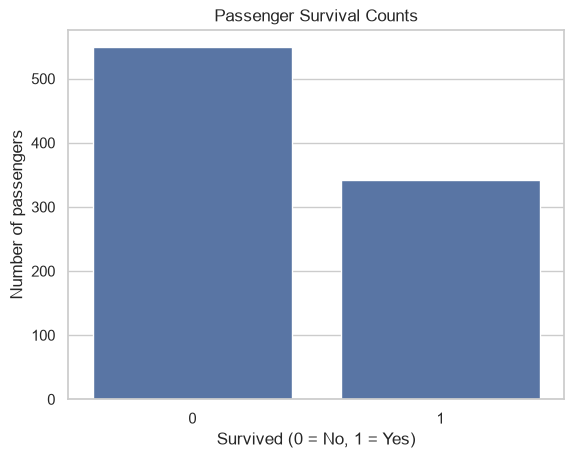

In [10]:
import matplotlib.pyplot as plt
import seaborn as sns

sns.countplot(data=df, x="Survived")
plt.title("Passenger Survival Counts")
plt.xlabel("Survived (0 = No, 1 = Yes)")
plt.ylabel("Number of passengers")
plt.show()

More passengers did not survive than survived

Age distribution

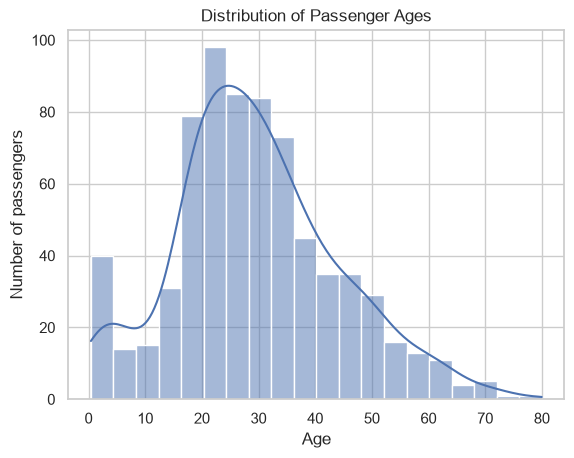

In [11]:
sns.histplot(data=df, x="Age", bins=20, kde=True)
plt.title("Distribution of Passenger Ages")
plt.xlabel("Age")
plt.ylabel("Number of passengers")
plt.show()

Age by survival

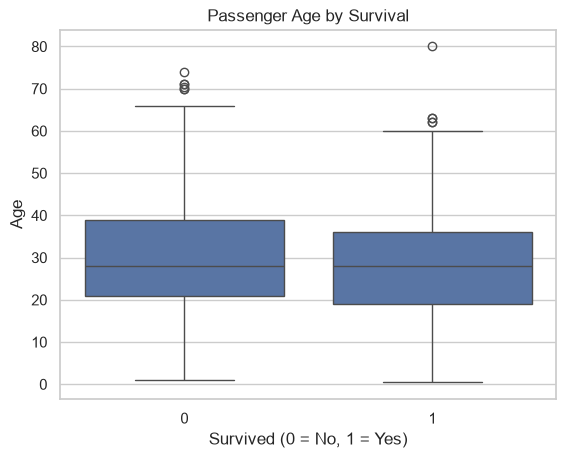

In [12]:
sns.boxplot(data=df, x="Survived", y="Age")
plt.title("Passenger Age by Survival")
plt.xlabel("Survived (0 = No, 1 = Yes)")
plt.ylabel("Age")
plt.show()

Fare compared with age

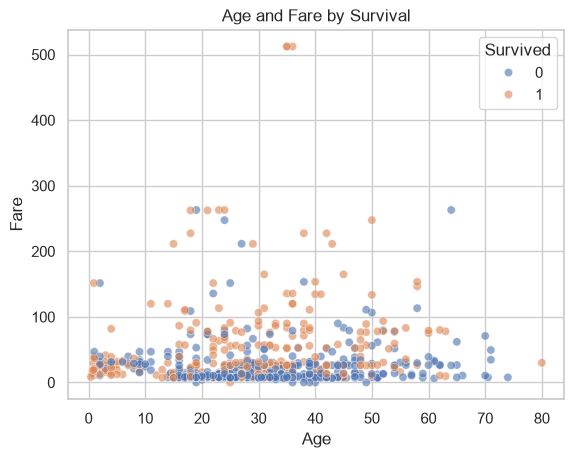

In [13]:
sns.scatterplot(data=df, x="Age", y="Fare", hue="Survived", alpha=0.6)
plt.title("Age and Fare by Survival")
plt.xlabel("Age")
plt.ylabel("Fare")
plt.show()

Heatmap of numeric-column relationships

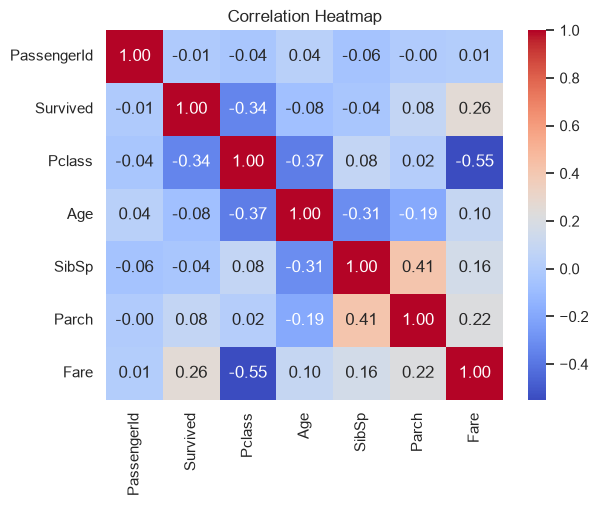

In [17]:
numeric_data = df.select_dtypes(include="number")

sns.heatmap(numeric_data.corr(), annot=True, cmap="coolwarm", fmt=".2f")
plt.title("Correlation Heatmap")
plt.show()

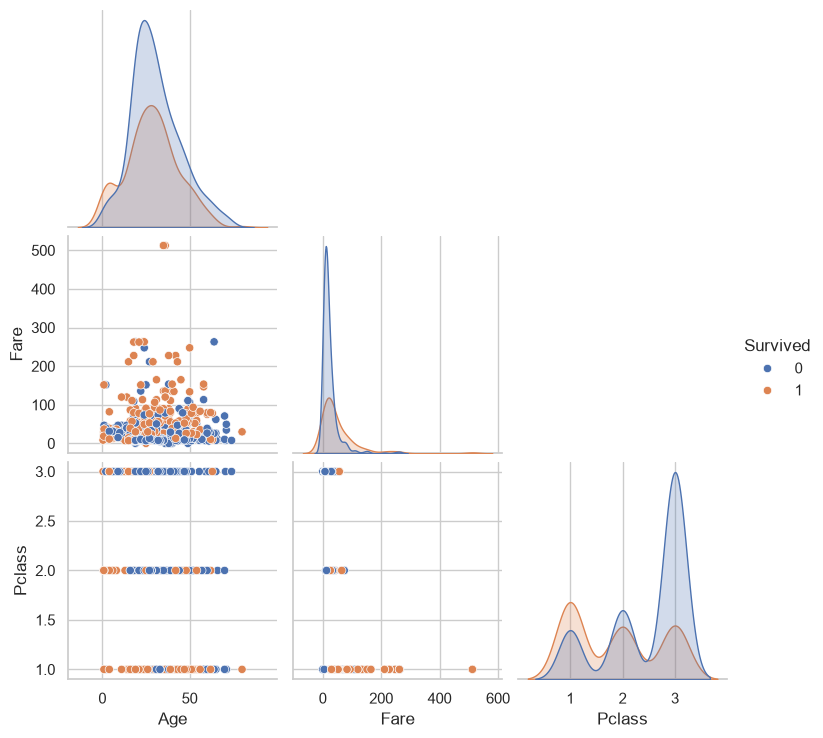

In [20]:
pair_data = df[["Age", "Fare", "Pclass", "Survived"]].dropna()
sns.pairplot(pair_data, hue="Survived", corner=True)
plt.show()

## Findings

- The dataset has 891 passengers and 12 columns.
- Age has 177 missing values, Cabin has 687, and Embarked has 2.
- 342 passengers survived and 549 did not.
- The survival rate was higher for women (74.2%) than men (18.9%).
- Survival rates were 63.0% in 1st class, 47.3% in 2nd class, and 24.2% in 3rd class.
- Most passengers with recorded ages in the age chart are in their 20s and 30s.
- These are patterns in this dataset; they do not prove cause and effect.

## Conclusion

This exploratory analysis found patterns in passenger age, fare, passenger class,
sex, and survival. These are observations from this dataset and do not prove cause
and effect.